# code_055 · Imputation and native missing-value handling

**Book:** section 11.4. A self-contained preprocessing laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_11_GUIDE.md), [run evidence](../CHAPTER_11_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_055).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Construction audits are distinct from predictive assessment; fitted examples declare training/development/final roles locally. All numerical data are generated. Model-family comparisons and documentary contract checks retain their declared limits; there are no field-validity or universal-preprocessing claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1155;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1155


<a id="mechanism"></a>
## A controlled missingness shift with unchanged reference targets

Generate 800 independent members. x2~Normal(0,1), x1=.7*x2+Normal(0,.7); displacement y=1.2*x1+.5*x2+.7*sin(x1)+Normal(0,.2) mm. Train/development/final roles are 450/150/200. During training/development, first-input dropout probability is .15+.5*sigmoid(x2). The same 200 final members receive two separately generated masks: matched dropout and shifted .65-.5*sigmoid(x2). All final raw features and targets are identical between regimes. Neither final regime selects a model; both are diagnostic challenges to frozen procedures.

Five procedures: median+indicator+standardization+Ridge alpha=1; 5-neighbor imputation+standardization+Ridge; five independently seeded BayesianRidge posterior-draw iterative imputers (10 iterations each), each followed by StandardScaler/Ridge, with mean prediction; native-NaN histogram boosting; and median+indicator histogram boosting with the same tree controls (80 iterations, 7 leaves, minimum leaf 15, learning rate .1, no early stopping). The linear/tree comparisons change estimator family as well as preprocessing. The two tree routes hold family controls fixed. Conditional imputers use the two similarly scaled inputs only, never target y.


In [2]:
from sklearn.impute import SimpleImputer,KNNImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge,Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error
n=800;x2=rng.normal(size=n);x1=.7*x2+rng.normal(0,.7,n);X=np.column_stack([x1,x2]);y=1.2*x1+.5*x2+.7*np.sin(x1)+rng.normal(0,.2,n)
tr=np.arange(450);dv=np.arange(450,600);te=np.arange(600,800)
p=.15+.5/(1+np.exp(-x2));observed=X.copy();mask=rng.random(n)<p;observed[mask,0]=np.nan
matched=observed[te].copy();shifted=X[te].copy();shiftmask=rng.random(200)<(.65-.5/(1+np.exp(-x2[te])));shifted[shiftmask,0]=np.nan
assert np.array_equal(matched[:,1],shifted[:,1]) and np.array_equal(y[te],y[te].copy())
def tree():return HistGradientBoostingRegressor(max_iter=80,max_leaf_nodes=7,min_samples_leaf=15,learning_rate=.1,early_stopping=False,random_state=SEED)
models={'median_indicator_ridge':make_pipeline(SimpleImputer(strategy='median',add_indicator=True),StandardScaler(),Ridge(alpha=1)),'knn_impute_ridge':make_pipeline(KNNImputer(n_neighbors=5),StandardScaler(),Ridge(alpha=1)),'native_tree':tree(),'median_indicator_tree':make_pipeline(SimpleImputer(strategy='median',add_indicator=True),tree())}
for fit in models.values():fit.fit(observed[tr],y[tr])
assert not set(tr)&set(dv) and not set(tr)&set(te) and not set(dv)&set(te)
np.testing.assert_allclose(models['median_indicator_ridge'][0].statistics_,np.nanmedian(observed[tr],axis=0))
# Fit separate stochastic imputation/model pairs, keeping all state inside training.
draws=[]
for j in range(5):
 imp=IterativeImputer(estimator=BayesianRidge(),sample_posterior=True,max_iter=10,random_state=SEED+j,skip_complete=True);Z=imp.fit_transform(observed[tr]);fit=make_pipeline(StandardScaler(),Ridge(alpha=1)).fit(Z,y[tr]);draws.append((imp,fit))
RESULTS['missing_fraction']={'train':float(mask[tr].mean()),'matched_final':float(np.isnan(matched[:,0]).mean()),'shifted_final':float(shiftmask.mean())};RESULTS['posterior_imputation_draws']=5


<a id="assessment"></a>
## Assess frozen procedures on each regime

Posterior draws induce variability across completed-input predictions. Their spread is only this model's imputation sensitivity, not calibrated predictive uncertainty or Rubin-pooled parameter inference. A new transform with sample_posterior=True consumes random state; exact deployment replay must preserve its draw policy. The saved run reports one declared sequence of transforms. Native missing routes also use learned state and may learn a predictive acquisition pattern that changes at deployment.


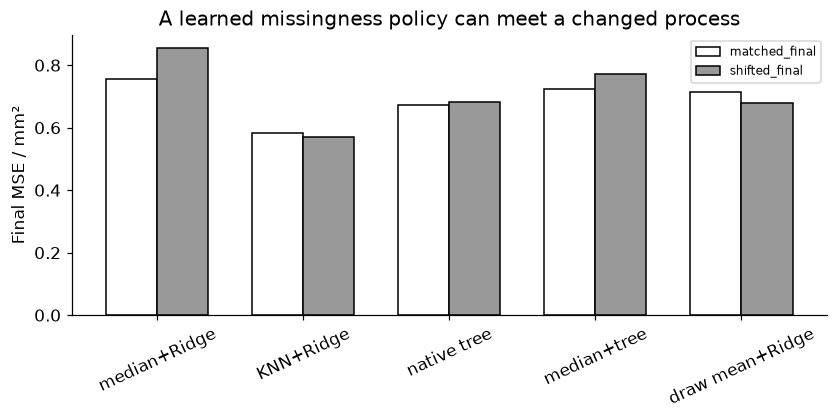

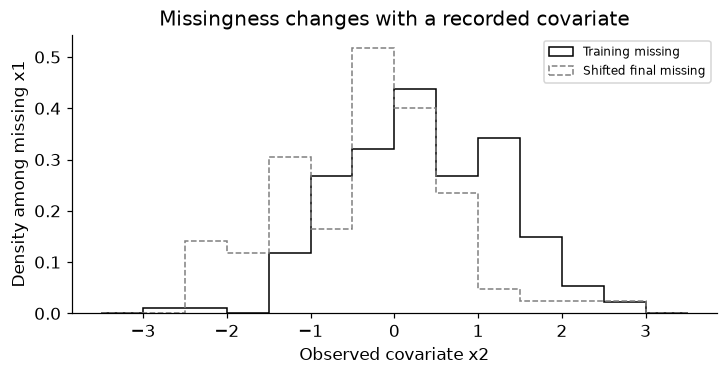

In [3]:
metrics={};spread={}
for name,A,truth in [('development',observed[dv],y[dv]),('matched_final',matched,y[te]),('shifted_final',shifted,y[te])]:
 metrics[name]={key:float(mean_squared_error(truth,fit.predict(A))) for key,fit in models.items()}
 P=np.array([fit.predict(imp.transform(A)) for imp,fit in draws]);assert P.shape==(5,len(A)) and np.isfinite(P).all()
 metrics[name]['posterior_draw_mean_ridge']=float(mean_squared_error(truth,P.mean(axis=0)));spread[name]=float(P.std(axis=0,ddof=1).mean())
RESULTS['MSE_mm2']=metrics;RESULTS['mean_imputation_prediction_sd_mm']=spread
fig,ax=plt.subplots(figsize=(7.5,3.7));names=list(metrics['matched_final']);k=np.arange(len(names))
for j,regime in enumerate(['matched_final','shifted_final']):ax.bar(k+(j-.5)*.35,[metrics[regime][m] for m in names],.35,color=['white','.6'][j],edgecolor='black',label=regime)
ax.set(xticks=k,xticklabels=['median+Ridge','KNN+Ridge','native tree','median+tree','draw mean+Ridge'],ylabel='Final MSE / mm²',title='A learned missingness policy can meet a changed process');ax.tick_params(axis='x',labelrotation=25);ax.legend(fontsize=8);plt.show()
fig,ax=plt.subplots(figsize=(6.5,3.3));bins=np.linspace(-3.5,3.5,15);ax.hist(x2[tr][mask[tr]],bins=bins,density=True,histtype='step',color='black',label='Training missing');ax.hist(x2[te][shiftmask],bins=bins,density=True,histtype='step',ls='--',color='.5',label='Shifted final missing');ax.set(xlabel='Observed covariate x2',ylabel='Density among missing x1',title='Missingness changes with a recorded covariate');ax.legend(fontsize=8);plt.show()


In [4]:
summary={'example_id':'code_055','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['simple and conditional imputation', 'posterior-draw predictive averaging', 'native tree missing-value routes', 'same-cohort missingness-shift assessment'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["simple and conditional imputation", "posterior-draw predictive averaging", "native tree missing-value routes", "same-cohort missingness-shift assessment"], "elapsed_seconds": 0.401, "example_id": "code_055", "hardware": "Darwin arm64 CPU", "results": {"MSE_mm2": {"development": {"knn_impute_ridge": 0.8205669319965201, "median_indicator_ridge": 0.9486479720538982, "median_indicator_tree": 0.8808484521873167, "native_tree": 0.8870329809621571, "posterior_draw_mean_ridge": 0.9465186678789678}, "matched_final": {"knn_impute_ridge": 0.58162535640604, "median_indicator_ridge": 0.756603998600206, "median_indicator_tree": 0.7238500694987222, "native_tree": 0.6730919817178064, "posterior_draw_mean_ridge": 0.7136052272049699}, "shifted_final": {"knn_impute_ridge": 0.5694840722634279, "median_indicator_ridge": 0.8548552654394075, "median_indicator_tree": 0.7730579541623608, "native_tree": 0.6827315415247942, "posterior_draw_mean_ridge": 0.6780377